# 3. Apply the HMM to a recording

This notebook applies a trained TDE-HMM to a recording and describes the
states it finds: state time courses, state spectra and summary statistics of
the state dynamics. By default it uses the released HUP model in `hup-model/`
(trained on 45 subjects of the HUP cohort); set `MODEL_DIR` to `my_model` to
use the model trained in `2_train.ipynb`. The last section compares the two.

The example recording is one held-out subject (HUP116), preprocessed in
`1_preprocess.ipynb`. Any recording preprocessed the same way can be used.

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

STATE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

from scipy.optimize import linear_sum_assignment

from osl_dynamics.analysis import spectral
from osl_dynamics.data import Data
from osl_dynamics.inference import modes
from osl_dynamics.models import load

## 1. Load the model

The model directory contains the osl-dynamics model (`config.yml`,
`model.weights.h5`), the PCA projection applied to the time-delay embedded data
before it enters the HMM (`pca_components.npy`), and `model_info.json` with the
settings and, for the released model, details of its training data and model
selection.

In [2]:
MODEL_DIR = Path("hup-model")              # or Path("my_model") after 2_train.ipynb

model = load(MODEL_DIR)
pca_components = np.load(MODEL_DIR / "pca_components.npy")
info = json.loads((MODEL_DIR / "model_info.json").read_text())

n_states = info["n_states"]
STATE_NAMES = [f"State {k + 1}" for k in range(n_states)]
print(f"{n_states}-state model from {MODEL_DIR}/: {info['state_order']}")

[15:10:06] Loading model: hup-model


4-state model from hup-model/: States are in the canonical order, defined on held-out subjects: the broadband state (most 13-45 Hz power) is State 1, the rest follow in descending 1-4 Hz power; model state k (0-indexed) is State k+1


## 2. Load a preprocessed recording

Preprocessing must match the training data (see `1_preprocess.ipynb`): good
contacts, bipolar reference, notch and 0.1-45 Hz band-pass filters, 100 Hz.

In [3]:
z = np.load("data/preprocessed/sub-HUP116.npz")
x, ch_names, sfreq = z["data"], list(z["channels"]), float(z["sfreq"])
assert sfreq == info["sampling_frequency_hz"]
print(f"{len(ch_names)} bipolar channels, {x.shape[1] / sfreq:.0f} s at {sfreq:.0f} Hz")

37 bipolar channels, 300 s at 100 Hz


## 3. Infer the state probabilities

Each channel is passed to osl-dynamics as a separate time series. `tde_pca`
time-delay embeds each channel and projects it onto the model's PCA components
(these must be the components saved with the model, not new ones);
`standardize` z-scores the components of each channel. The HMM then infers the
probability of each state at every time point (`alpha`).

Embedding and batching into sequences remove a few samples from the start and
end of each channel, so `alpha` is slightly shorter than the input (its first
sample is input sample `n_embeddings // 2`). `trim_time_series` returns the
signal aligned sample-for-sample with `alpha`, and `argmax_time_courses` gives
the most probable state at each time point.

In [4]:
data = Data([ch[:, None] for ch in x])
data.prepare({
    "tde_pca": {"n_embeddings": info["n_embeddings"], "pca_components": pca_components},
    "standardize": {},
})
alpha = model.get_alpha(data)                                  # list of (n_samples, n_states)
signal = data.trim_time_series(sequence_length=info["sequence_length"], prepared=False)
stc = modes.argmax_time_courses(alpha)
print(f"{len(alpha)} channels, {alpha[0].shape[0]} samples, {n_states} states")

37 channels, 29800 samples, 4 states


## 4. State time course

Ten seconds of one channel, centred on its largest-amplitude event (ignoring
the first and last 10 s, which contain filter edge effects): the signal shaded
by the most probable state, and the state probabilities below. Change `ch` to
look at other channels; the broadband State 1 marks sharp transients such as
interictal discharges.

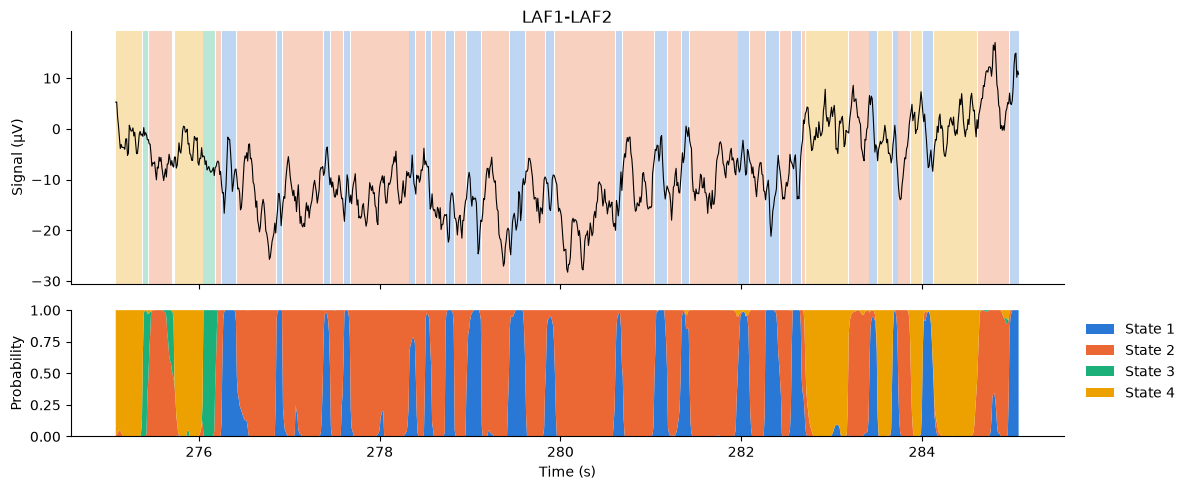

In [5]:
ch = 0                                     # any channel index
y = signal[ch][:, 0] * 1e6                 # microvolts
edge = int(10 * sfreq)
peak = edge + np.argmax(np.abs(y[edge:-edge]))
win = slice(max(peak - int(5 * sfreq), 0), peak + int(5 * sfreq))
t = (np.arange(len(y))[win] + info["n_embeddings"] // 2) / sfreq
state = stc[ch][win].argmax(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, height_ratios=[2, 1])
for k in range(n_states):
    ax1.fill_between(t, 0, 1, where=state == k, step="mid", transform=ax1.get_xaxis_transform(),
                     color=STATE_COLORS[k], alpha=0.3, lw=0)
ax1.plot(t, y[win], color="black", lw=0.8)
ax1.set(ylabel="Signal (µV)", title=ch_names[ch])
ax2.stackplot(t, alpha[ch][win].T, colors=STATE_COLORS[:n_states], labels=STATE_NAMES)
ax2.set(ylim=(0, 1), ylabel="Probability", xlabel="Time (s)")
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout()

## 5. State spectra

The power spectrum of each state is estimated with a multitaper method weighted
by the state probabilities, then averaged over channels.

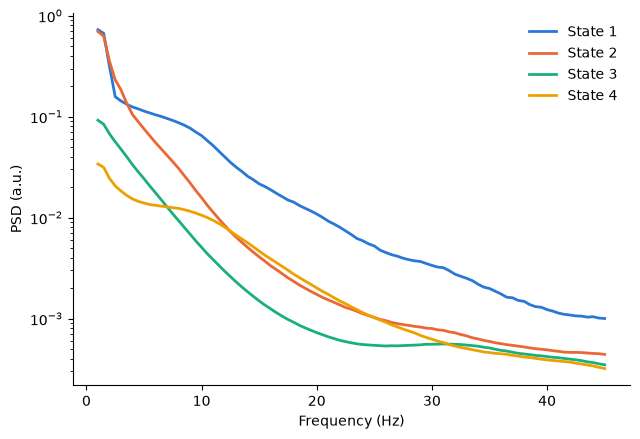

In [6]:
freqs, psd = spectral.multitaper_spectra(
    data=signal, alpha=alpha, sampling_frequency=sfreq, frequency_range=[1, 45], calc_coh=False,
)
psd = np.squeeze(psd)                      # (n_channels, n_states, n_freqs)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k in range(n_states):
    ax.semilogy(freqs, psd[:, k].mean(axis=0), color=STATE_COLORS[k], lw=2, label=STATE_NAMES[k])
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (a.u.)")
ax.legend(frameon=False)
fig.tight_layout()

## 6. Summary statistics

For every channel and state: fractional occupancy, mean lifetime, mean interval
and switching rate. These per-channel, per-state numbers are the quantities
compared between conditions, brain regions or trials in the paper.

,Fractional occupancy,Mean lifetime (ms),Mean interval (ms),Switching rate (/s)
State 1,0.151,139.578,1020.860,1.115
State 2,0.291,182.421,581.838,1.624
State 3,0.165,128.306,962.888,1.100
State 4,0.393,212.579,325.790,1.869


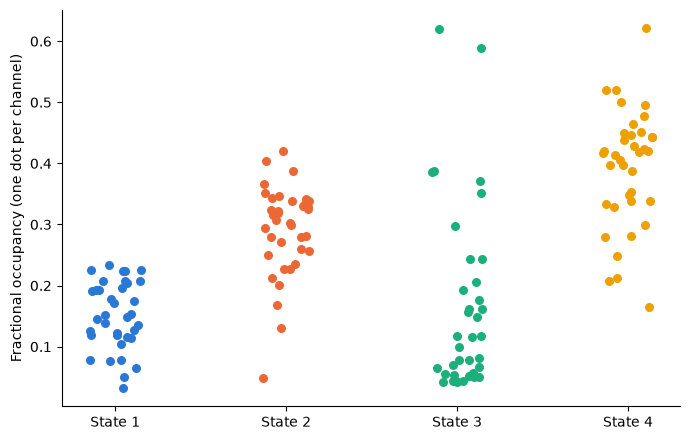

In [7]:
fo = modes.fractional_occupancies(stc)                          # (n_channels, n_states)
lt = modes.mean_lifetimes(stc, sampling_frequency=sfreq)        # s
iv = modes.mean_intervals(stc, sampling_frequency=sfreq)        # s
sr = modes.switching_rates(stc, sampling_frequency=sfreq)       # visits per second

display(pd.DataFrame({
    "Fractional occupancy": fo.mean(axis=0),
    "Mean lifetime (ms)": 1000 * np.nanmean(lt, axis=0),
    "Mean interval (ms)": 1000 * np.nanmean(iv, axis=0),
    "Switching rate (/s)": sr.mean(axis=0),
}, index=STATE_NAMES).round(3))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(n_states):
    ax.scatter(k + rng.uniform(-0.15, 0.15, len(fo)), fo[:, k], s=30, color=STATE_COLORS[k])
ax.set_xticks(range(n_states), STATE_NAMES)
ax.set_ylabel("Fractional occupancy (one dot per channel)")
fig.tight_layout()

## 7. Compare with the model trained in `2_train.ipynb`

Two models trained on different data find the "same" states if their state
probabilities agree over time. Here the model trained on four subjects in
`2_train.ipynb` (`my_model/`) is applied to the same recording and its states
are matched to the released model's by Hungarian assignment on the correlation
of the state probabilities. In the paper, models trained independently on two
cohorts (and on SEEG only or ECoG only) found the same four states; with a
4-subject training set the agreement is naturally lower.

[15:10:10] Loading model: my_model


my_model/ states matched to hup-model/ states: {'State 1': 'State 1 (r = 0.87)', 'State 2': 'State 2 (r = 0.83)', 'State 3': 'State 3 (r = 0.74)', 'State 4': 'State 4 (r = 0.71)'}
same most-probable state on 77% of samples


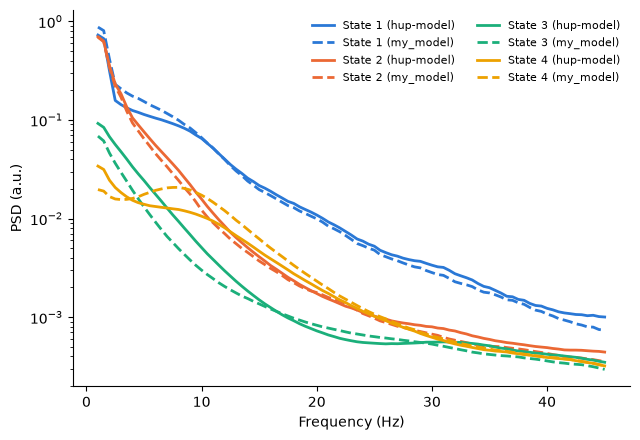

In [8]:
OTHER_DIR = Path("my_model")
if OTHER_DIR.exists():
    other = load(OTHER_DIR)
    other_pca = np.load(OTHER_DIR / "pca_components.npy")
    other_data = Data([ch[:, None] for ch in x])
    other_data.prepare({"tde_pca": {"n_embeddings": info["n_embeddings"], "pca_components": other_pca},
                        "standardize": {}})
    other_alpha = other.get_alpha(other_data)

    A, B = np.concatenate(alpha), np.concatenate(other_alpha)
    corr = np.corrcoef(A.T, B.T)[:n_states, n_states:]
    rows, cols = linear_sum_assignment(-corr)
    same = np.mean(np.argsort(cols)[B.argmax(1)] == A.argmax(1))
    print(f"{OTHER_DIR}/ states matched to {MODEL_DIR}/ states:",
          {f"State {r + 1}": f"State {c + 1} (r = {corr[r, c]:.2f})" for r, c in zip(rows, cols)})
    print(f"same most-probable state on {100 * same:.0f}% of samples")

    _, other_psd = spectral.multitaper_spectra(
        data=signal, alpha=other_alpha, sampling_frequency=sfreq, frequency_range=[1, 45], calc_coh=False,
    )
    other_psd = np.squeeze(other_psd)[:, cols]
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for k in range(n_states):
        ax.semilogy(freqs, psd[:, k].mean(axis=0), color=STATE_COLORS[k], lw=2, label=f"{STATE_NAMES[k]} ({MODEL_DIR})")
        ax.semilogy(freqs, other_psd[:, k].mean(axis=0), color=STATE_COLORS[k], lw=2, ls="--",
                    label=f"{STATE_NAMES[k]} ({OTHER_DIR})")
    ax.set(xlabel="Frequency (Hz)", ylabel="PSD (a.u.)")
    ax.legend(frameon=False, fontsize=8, ncol=2)
    fig.tight_layout()
else:
    print(f"{OTHER_DIR}/ not found: run 2_train.ipynb first to compare the two models")